### AI-EXAFS Ablation Study

In [1]:
# Imports
import json
import numpy as np
from scipy.stats import gaussian_kde
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# General Plot Settings
width = 4
fontsize = 16
rc = {'figure.figsize': (width, width),
      'font.size': fontsize,
      'axes.labelsize': fontsize,
      'axes.titlesize': fontsize,
      'xtick.labelsize': fontsize,
      'ytick.labelsize': fontsize,
      'legend.fontsize': fontsize-2.5}
sns.set(rc=rc)
sns.set_style('ticks')

In [3]:
# Metrics
def mae(y_true, predictions):
    """Function that computes the Mean Absolute Error between spectra"""
    y_true, predictions = np.array(y_true), np.array(predictions)
    return np.mean(np.abs(y_true - predictions))

def r_factor(y_true, predictions):
    """Function that computes the R-factor metric used in EXAFS comparison"""
    y_true, predictions = np.array(y_true), np.array(predictions)
    a = np.sum(np.square(y_true - predictions))
    b = np.sum(np.square(y_true))
    return np.divide(a, b)

In [4]:
# Helper Functions
def load_json(filename):
    with open(filename, "r") as j_file:
        pred_data = json.load(j_file)
    j_file.close()
    return pred_data

def get_array(a, b):
    """Function that when given (a,b) builds array with shape (2, N)"""
    arr = np.zeros((len(a), 2))
    arr[:, 0] = a
    arr[:, 1] = b
    return arr

def remove_duplicates(x):
    """Function that avoids duplicates in plots"""
    new_list, elm_list = [], []
    for n in x:
        elm = n.split("_")[1]
        if elm not in elm_list:
            elm_list.append(elm)
            new_list.append(n)
    return new_list

def get_bin_width(errors, bins="auto"):
    return np.diff(np.histogram_bin_edges(errors, bins=bins))[0]

In [5]:
# Collecting metrics for the whole test dataset (10%)
def get_metrics(pred_data):
    # Empty dictionaries
    metrics_dict_k = {"id": [], "mae": [], "r_factor": []}
    metrics_dict_r = {"id": [], "mae": [], "r_factor": []}
    # Loop over the data
    for n in range(len(pred_data)):
        # EXAFS K-space data
        target_chi = pred_data[n]["target_chi"]
        pred_chi = pred_data[n]["pred_chi"]
        # EXAFS K-space metrics
        mae_k = mae(target_chi, pred_chi)
        r_factor_k = r_factor(target_chi, pred_chi)
        # EXAFS R-space data
        target_chir_mag = pred_data[n]["target_chir_mag"]
        pred_chir_mag = pred_data[n]["pred_chir_mag"]
        # EXAFS R-space metrics
        mae_r = mae(target_chir_mag, pred_chir_mag)
        r_factor_r = r_factor(target_chir_mag, pred_chir_mag)
        # Append data into metrics dict (k-space)
        metrics_dict_k["id"].append(pred_data[n]["id"])
        metrics_dict_k["mae"].append(mae_k)
        metrics_dict_k["r_factor"].append(r_factor_k)
        # Append data into metrics dict (r-space)
        metrics_dict_r["id"].append(pred_data[n]["id"])
        metrics_dict_r["mae"].append(mae_r)
        metrics_dict_r["r_factor"].append(r_factor_r)
    return metrics_dict_k, metrics_dict_r

In [6]:
# Helper function to get the histogram curve
def plot_error_kde(ax, errors, label, color, lw, bin_width, alpha=1.0, zorder=2):
    kde = gaussian_kde(errors, bw_method="scott")
    x = np.linspace(min(errors) - 0.1, max(errors) + 0.1, 500)
    y = kde(x) * len(errors) * bin_width
    ax.plot(x, y, label=label, color=color, lw=lw, alpha=alpha, zorder=zorder)
    ax.fill_between(x, y, alpha=0.08 * alpha, color=color, zorder=zorder)

In [7]:
# Best Model First
pred_data_best = load_json(filename="./outputs/ablation/test_ai_exafs_ablation_best_model_1.json")

best_model_metrics_dict_k, best_model_metrics_dict_r = get_metrics(pred_data=pred_data_best)


In [8]:
# Grap Representation Ablation - Metrics
graph_file_dict = {
    "No Edge Features": "./outputs/ablation/test_ai_exafs_ablation_no_edge_attr_2.json",
    "No SS Paths": "./outputs/ablation/test_ai_exafs_ablation_no_SSpath_3.json",
}

# Loop over ablation files to get metrics dict
graph_ablation_dict_rfactor, graph_ablation_dict_mae = {}, {}
for label, filename in graph_file_dict.items():
    # Load json file
    pred_data = load_json(filename=filename)
    # Get metrics
    metrics_dict_k, metrics_dict_r = get_metrics(pred_data=pred_data)
    # Append to the dict
    graph_ablation_dict_rfactor.update({str(label): metrics_dict_k["r_factor"]})
    graph_ablation_dict_mae.update({str(label): metrics_dict_k["mae"]})


In [9]:
# Model Ablation - Metrics
model_file_dict = {
    "No Residual Block": "./outputs/ablation/test_ai_exafs_ablation_no_residualblock_4.json",
    "No Attention (global_mean_pool)": "./outputs/ablation/test_ai_exafs_ablation_no_Attention_mean_7.json",
    "No Attention (global_max_pool)": "./outputs/ablation/test_ai_exafs_ablation_no_Attention_max_8.json",
    "No Sigmoid": "./outputs/ablation/test_ai_exafs_ablation_no_Sigmoid_9.json",
}

# Loop over ablation files
model_ablation_dict_rfactor, model_ablation_dict_mae = {}, {}
for label, filename in model_file_dict.items():
    # Load json file
    pred_data = load_json(filename=filename)
    # Get metrics
    metrics_dict_k, metrics_dict_r = get_metrics(pred_data=pred_data)
    # Append
    model_ablation_dict_rfactor.update({str(label): metrics_dict_k["r_factor"]})
    model_ablation_dict_mae.update({str(label): metrics_dict_k["mae"]})

In [10]:
# Training Ablation - Metrics
training_file_dict = {
    "No R-Factor (MAE)": "./outputs/ablation/test_ai_exafs_ablation_no_rfactorloss_10.json",
    "No R-Factor (MSE)": "./outputs/ablation/test_ai_exafs_ablation_no_rfactorloss_mse_12.json",
    "No R-Factor (SID)": "./outputs/ablation/test_ai_exafs_ablation_no_rfactorloss_sid_13.json",
}

# Loop over ablation files
training_ablation_dict_rfactor, training_ablation_dict_mae = {}, {}
for label, filename in training_file_dict.items():
    # Load json file
    pred_data = load_json(filename=filename)
    # Get metrics
    metrics_dict_k, metrics_dict_r = get_metrics(pred_data=pred_data)
    # Append
    training_ablation_dict_rfactor.update({str(label): metrics_dict_k["r_factor"]})
    training_ablation_dict_mae.update({str(label): metrics_dict_k["mae"]})

In [11]:
# Panels
panels_r_factor = [
    ("Graph Representation", best_model_metrics_dict_k["r_factor"], graph_ablation_dict_rfactor, (0, 0.6)),
    ("Model Architecture", best_model_metrics_dict_k["r_factor"], model_ablation_dict_rfactor, (0, 0.3)),
    ("Training", best_model_metrics_dict_k["r_factor"], training_ablation_dict_rfactor, (0, 0.3)),
]

panels_mae = [
    ("Graph Representation", best_model_metrics_dict_k["mae"], graph_ablation_dict_mae, (0, 0.35)),
    ("Model Architecture", best_model_metrics_dict_k["mae"], model_ablation_dict_mae, (0, 0.35)),
    ("Training", best_model_metrics_dict_k["mae"], training_ablation_dict_mae, (0, 0.35)),
]

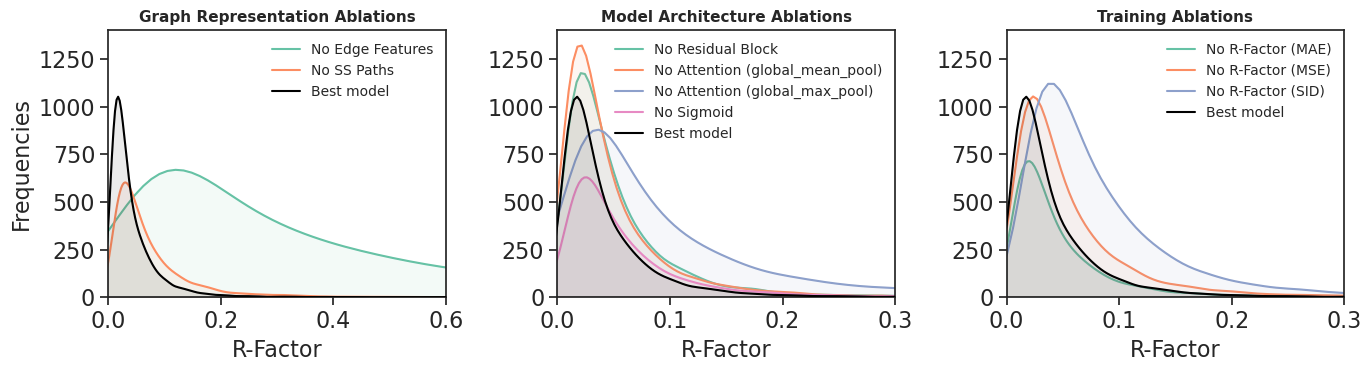

In [12]:
# Figure - Kspace (R-factor)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=False)

for i, (ax, (title, best_errors, ablation_dict, xlim)) in enumerate(zip(axes, panels_r_factor)):
    # Select colors
    colors = sns.color_palette("Set2", n_colors=len(ablation_dict))
    for (name, errs), color in zip(ablation_dict.items(), colors):
        # get bin width
        bw = get_bin_width(errs)
        plot_error_kde(ax, errs, label=name, color=color, lw=1.5, bin_width=bw, zorder=1)

    # Best model
    bw_best = get_bin_width(best_errors)
    plot_error_kde(ax, best_errors, label="Best model", color="black", bin_width=bw_best, lw=1.5, zorder=3)

    # Labels
    ax.set_title(f"{title} Ablations", fontsize=11, fontweight="bold")
    ax.set_xlabel("R-Factor")
    ax.set_ylabel("Frequencies" if i == 0 else "")
    ax.legend(fontsize=10, framealpha=0.5, frameon=False, loc="upper right")
    ax.set_xlim(*xlim)
    ax.set_ylim(0.0, 1400)
    #sns.despine(ax=ax)

plt.tight_layout()
plt.savefig("./hist_ablation_rfactor.png", dpi=200)

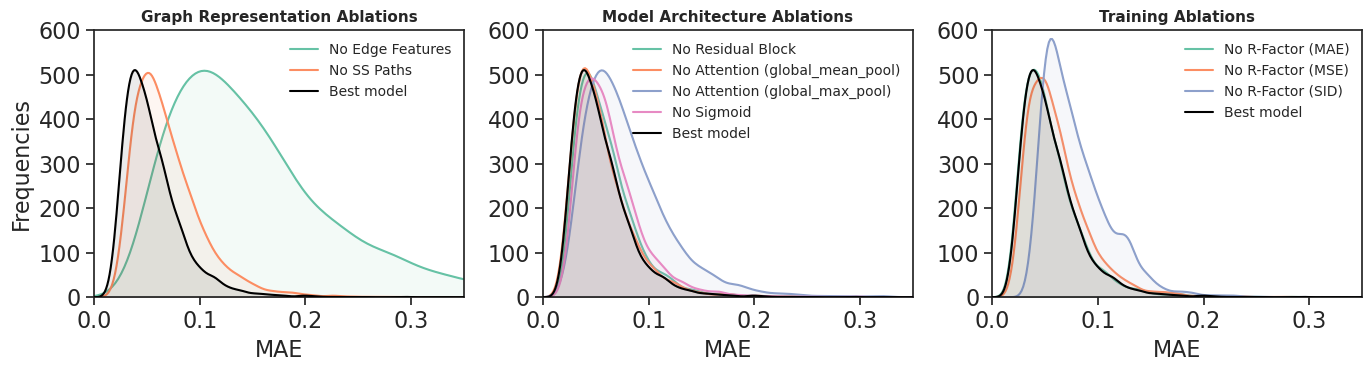

In [13]:
# Figure - Kspace (MAE)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=False)

for i, (ax, (title, best_errors, ablation_dict, xlim)) in enumerate(zip(axes, panels_mae)):
    # Select colors
    colors = sns.color_palette("Set2", n_colors=len(ablation_dict))
    for (name, errs), color in zip(ablation_dict.items(), colors):
        # get bin width
        bw = get_bin_width(errs)
        plot_error_kde(ax, errs, label=name, color=color, lw=1.5, bin_width=bw, zorder=1)

    # Best model
    bw_best = get_bin_width(best_errors)
    plot_error_kde(ax, best_errors, label="Best model", color="black", bin_width=bw_best, lw=1.5, zorder=3)

    # Labels
    ax.set_title(f"{title} Ablations", fontsize=11, fontweight="bold")
    ax.set_xlabel("MAE")
    ax.set_ylabel("Frequencies" if i == 0 else "")
    ax.legend(fontsize=10, framealpha=0.5, frameon=False, loc="upper right")
    ax.set_xlim(*xlim)
    ax.set_ylim(0.0, 600)
    #sns.despine(ax=ax)

plt.tight_layout()
plt.savefig("./hist_ablation_mae.png", dpi=200)

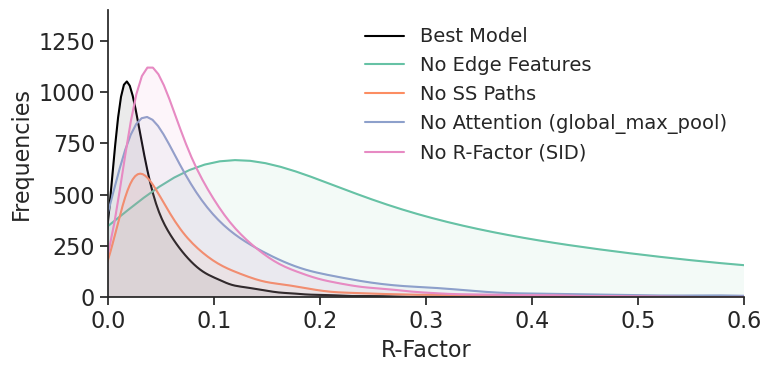

In [14]:
# Ablation figure for main 
selected = {
    "Best Model":           best_model_metrics_dict_k["r_factor"],
    "No Edge Features":     graph_ablation_dict_rfactor["No Edge Features"],
    "No SS Paths":          graph_ablation_dict_rfactor["No SS Paths"],
    "No Attention (global_max_pool)": model_ablation_dict_rfactor["No Attention (global_max_pool)"],
    "No R-Factor (SID)":    training_ablation_dict_rfactor["No R-Factor (SID)"],
}

colors = ["black"] + sns.color_palette("Set2", n_colors=len(selected) - 1)

fig, ax = plt.subplots(figsize=(8, 4))

for (name, errs), color in zip(selected.items(), colors):
    bw = get_bin_width(errs)
    lw = 2.0 if name == "Best model" else 1.5
    zorder = 3 if name == "Best model" else 1
    plot_error_kde(ax, errs, label=name, color=color, lw=lw, bin_width=bw, zorder=zorder)

ax.set_xlabel("R-Factor")
ax.set_ylabel("Frequencies")
ax.set_xlim(0, 0.6)
ax.set_ylim(0, 1400)
ax.legend(fontsize=14, framealpha=0.5, frameon=False, loc="upper right")
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig("./hist_condensed_rfactor.svg")

## Degradation showcases

In [15]:
# Selected ablation experiments
ABLATION_FILES = {
    "Best Model":              pred_data_best,
    "No Edge Features":        load_json("./outputs/ablation/test_ai_exafs_ablation_no_edge_attr_2.json"),
    "No SS Paths":             load_json("./outputs/ablation/test_ai_exafs_ablation_no_SSpath_3.json"),
    "No Attention (max pool)": load_json("./outputs/ablation/test_ai_exafs_ablation_no_Attention_max_8.json"),
    "No R-Factor (SID)":       load_json("./outputs/ablation/test_ai_exafs_ablation_no_rfactorloss_sid_13.json"),
}

In [16]:
def _build_records(ablation_files):
    records = {}
    for label, pred_data in ablation_files.items():
        for entry in pred_data:
            mol_id = entry["id"]
            if mol_id not in records:
                records[mol_id] = {}
            records[mol_id][label] = entry
    # Keep only molecules present in all experiments
    all_labels = list(ablation_files.keys())
    records = {k: v for k, v in records.items() if all(lbl in v for lbl in all_labels)}
    return records, all_labels

In [17]:
_records, _labels = _build_records(ABLATION_FILES)
# Colors matching the condensed histogram figure (Set2 palette, same order)
_colors = ["black"] + sns.color_palette("Set2", n_colors=len(_labels) - 1)

In [18]:
def plot_single(mol_id, space="k"):
    """
    Plot the ablation sequence for a single molecule.
    """
    # Resolve partial id (metal+edge suffix)
    if mol_id not in _records:
        matches = [k for k in _records if k.endswith(mol_id)]
        if len(matches) == 1:
            mol_id = matches[0]
            print(f"Resolved to: {mol_id}")
        elif len(matches) > 1:
            raise ValueError(f"Ambiguous: '{mol_id}' matches {len(matches)} entries — use the full id.")
        else:
            raise KeyError(f"'{mol_id}' not found in records.")

    parts    = mol_id.split("_")
    short_id = "_".join(parts[1:]) if len(parts) >= 3 else mol_id

    space_cfg = {
        "k": ("target_chi",      "pred_chi",      "target_k", r"$k$ (Å$^{-1}$)", r"$\chi(k)\cdot k^{2}$",   (0.0, 12.0)),
        "R": ("target_chir_mag", "pred_chir_mag", "target_r", r"$R$ (Å)",        r"$|\chi(R)|$", (0.0,  6.0)),
    }
    spaces = ["k", "R"] if space == "both" else [space]
    figs   = []

    for sp in spaces:
        chi_key, pred_key, x_key, xlabel, ylabel, xlim = space_cfg[sp]

        # R-factors across experiments
        rf_vals = [r_factor(_records[mol_id][lbl]["target_chi"],
                            _records[mol_id][lbl]["pred_chi"])
                    for lbl in _labels]

        fig, axes = plt.subplots(1, len(_labels),
                                figsize=(3.2 * len(_labels), 3.2),
                                sharey=False)
        fig.suptitle(f"{short_id}  —  EXAFS {sp}-space ablation",
                    fontsize=11, fontweight="bold", y=1.02)

        for col_idx, (ax, label, rf) in enumerate(zip(axes, _labels, rf_vals)):
            entry  = _records[mol_id][label]
            x_tgt  = np.array(entry[x_key])
            y_tgt  = np.array(entry[chi_key])
            x_pred = x_tgt if sp == "k" else np.array(entry.get("target_r", entry[x_key]))
            y_pred = np.array(entry[pred_key])
            color  = _colors[col_idx]

            ax.plot(x_tgt,  y_tgt,  color="black", lw=1.3, ls="--", zorder=3)
            ax.plot(x_pred, y_pred, color=color,   lw=1.3,          zorder=2)

            # Hard x-limits: kills the default 5% autoscale padding
            ax.margins(x=0)
            ax.set_xlim(*xlim)

            # R-factor annotation
            ax.text(0.97, 0.95, f"R = {rf:.4f}",
                    transform=ax.transAxes, ha="right", va="top",
                    fontsize=8, color="black",
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7))

            ax.set_title(label, fontsize=9, fontweight="bold", pad=6)
            ax.set_xlabel(xlabel, fontsize=9)
            ax.set_ylabel(ylabel if col_idx == 0 else "", fontsize=9)
            ax.tick_params(labelsize=8)
            #sns.despine(ax=ax)

        handles = [
            plt.Line2D([0], [0], color="black", lw=1.3, ls="--", label="Target"),
            plt.Line2D([0], [0], color="gray",  lw=1.3,          label="Predicted"),
        ]
        #fig.legend(handles=handles, loc="lower center", ncol=2,
        #           fontsize=9, framealpha=0.5, bbox_to_anchor=(0.5, -0.05))
        plt.tight_layout()

        figs.append(fig)

    return figs[0] if len(figs) == 1 else figs

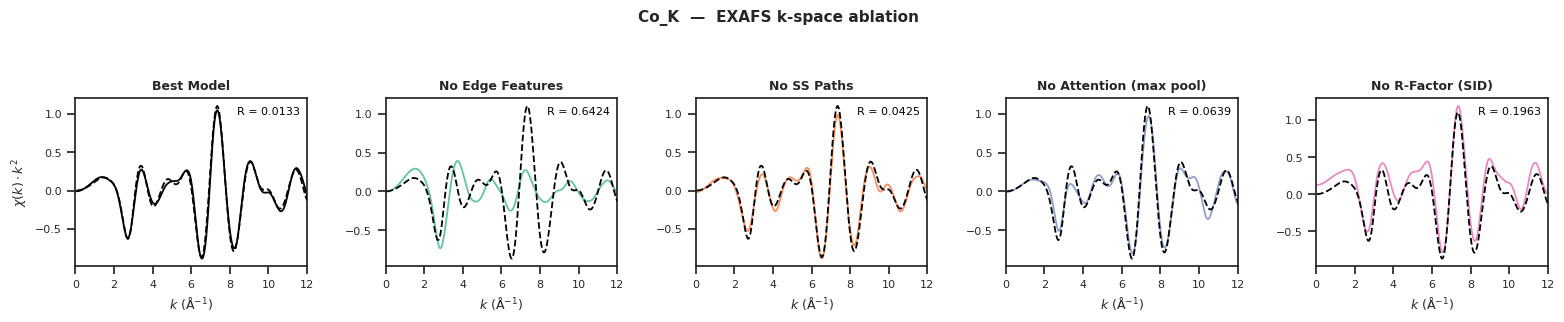

In [19]:
plot_single("dfee6bcb-10b9-4f0e-9118-3477e3a7c933_Co_K", space="k")
plt.savefig("./Co_ablation_showcase_kspace.svg")

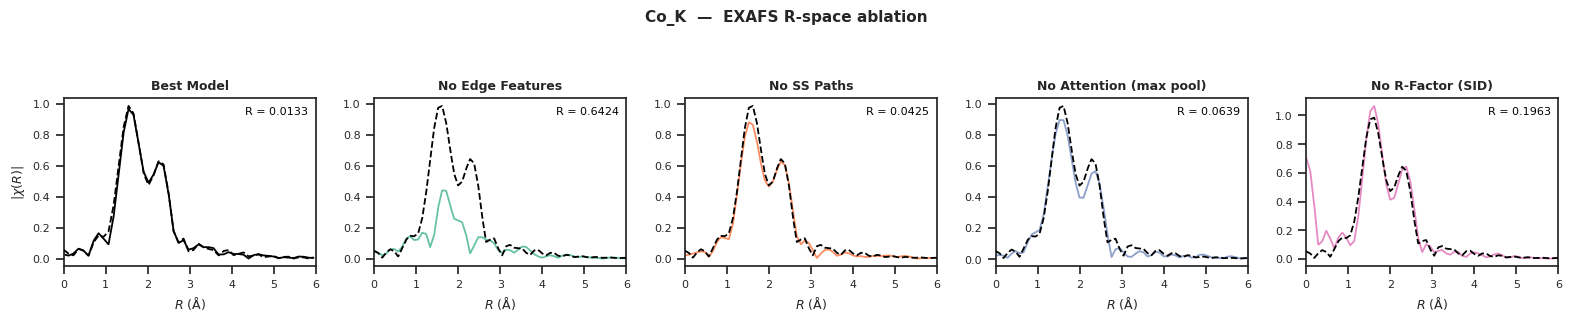

In [20]:
plot_single("dfee6bcb-10b9-4f0e-9118-3477e3a7c933_Co_K", space="R")
plt.savefig("./Co_ablation_showcase_rspace.svg")

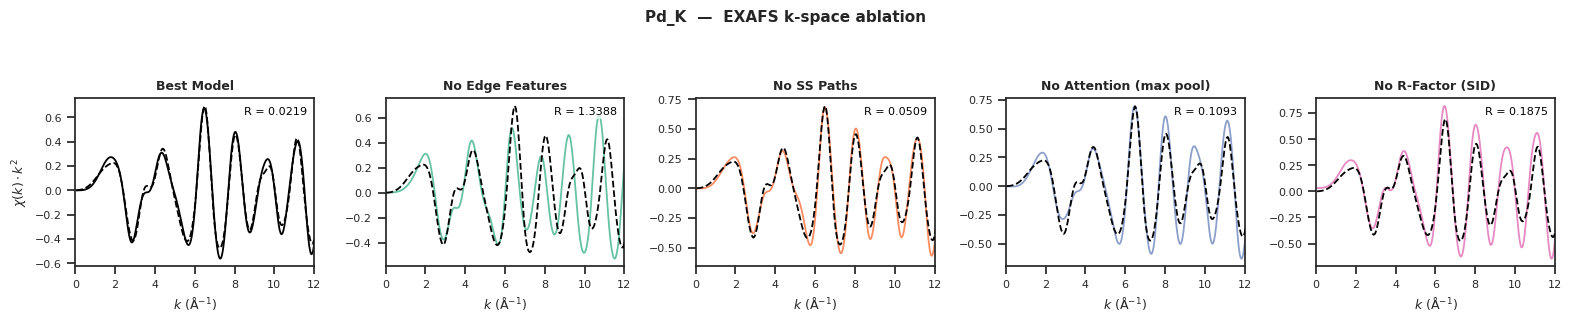

In [21]:
plot_single("b8e64f46-b310-4f73-b745-38ad22eefe9e_Pd_K", space="k")
plt.savefig("./Pd_ablation_showcase_kspace.svg")

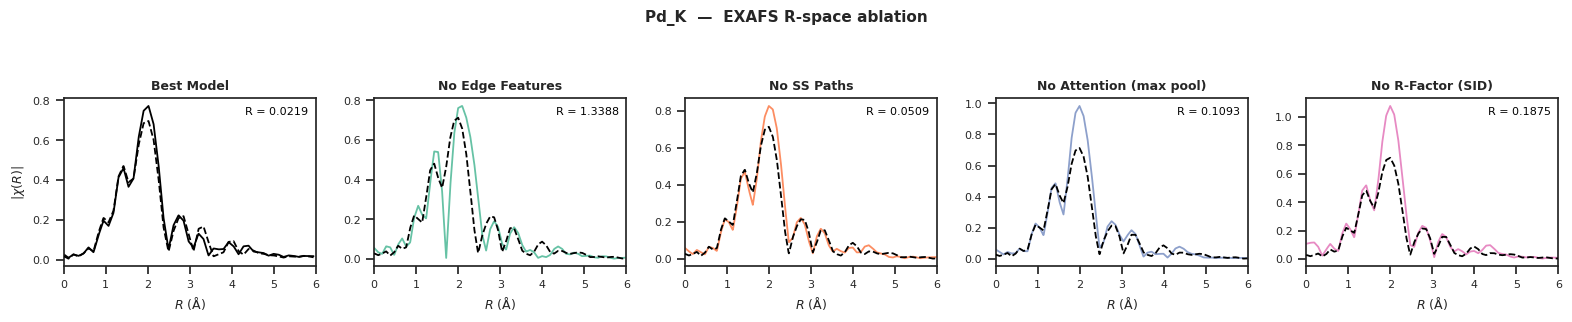

In [22]:
plot_single("b8e64f46-b310-4f73-b745-38ad22eefe9e_Pd_K", space="R")
plt.savefig("./Pd_ablation_showcase_rspace.svg")